# Clasificación de imágenes de resonancia magnética para la detección de tumores cerebrales
---
_Andrea Real Blanco_ 

El conjunto de datos empleado consta de un total de 253 imágenes, de las cuales 155 han sido identificadas como con tumor y 98 sin tumor. El propósito de este trabajo es aplicar técnicas de machine learning, centrándonos en redes neuronales artificiales, concretamente redes convolucionales, y máquinas de soporte vectorial, para llevar a cabo la clasificación de imágenes de resonancia magnética (MRI) en dos categorías: con tumor o sin tumor.

**Contenidos**:
1. [Preprocesado](#preprocessing)
2. [Clasificación con redes neuronales convolucionales (CNN)](#cnn-classification)
3. [Clasificación con máquinas de soporte vectorial (SVM)](#svm-classification)
4. [Conclusión](#conclusion)

**Dataset**: [Brain MRI Images for Brain Tumor Detection (Kaggle)](https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection/data)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Preprocesado
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# CNN
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

# SVM
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score 

## **1. Preprocesado** <a class="anchor" id="preprocessing"></a>


In [3]:
data_directory = "brain-mri-dataset/"

In [4]:
# Creamos un DataFrame con el nombre de las imágenes y sus etiquetas
file_names = []
labels = []

for folder in os.listdir(data_directory):
    folder_path = os.path.join(data_directory, folder)

    if os.path.isdir(folder_path):
        for file_name in os.listdir(folder_path):
            file_path = os.path.join(folder_path, file_name)

            file_names.append(file_name)
            labels.append(folder)
            
df = pd.DataFrame({'image': file_names, 'tumor': labels})
display(df)

FileNotFoundError: [WinError 3] El sistema no puede encontrar la ruta especificada: 'brain-mri-dataset/'

In [4]:
# Diagrama circular para ver la distribución de imágenes de cada tipo
#count_tumor = df['tumor'].value_counts()
#plt.pie(count_tumor, labels=count_tumor.index, autopct=lambda p: '{:.0f}'.format(p * sum(count_tumor) / 100))
#plt.title('Distribución de imágenes con tumor y sin tumor')
#plt.show()

In [5]:
# Para suministrar las imágenes a los modelos es necesario que todas tengan las mismas dimensiones y que estén en forma de matriz
image_arrays = []
labels = df['tumor'].tolist()
target_size = (250, 250) # Dimensiones para las imágenes

for index, row in df.iterrows():
    img_path = os.path.join(data_directory, row['tumor'], row['image'])
    img = load_img(img_path, target_size=target_size) # Redimensión
    img_array = img_to_array(img) # Imagen a array
    image_arrays.append(img_array)

# Convertimos a numpy arrays
image_arrays = np.array(image_arrays)

# Codificamos las variables categóricas ('yes' o 'no') como vectores binarios
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels)
labels_array = to_categorical(encoded_labels)

# Normalizamos los valores de los píxeles [0, 255]
image_arrays = image_arrays / 255.0

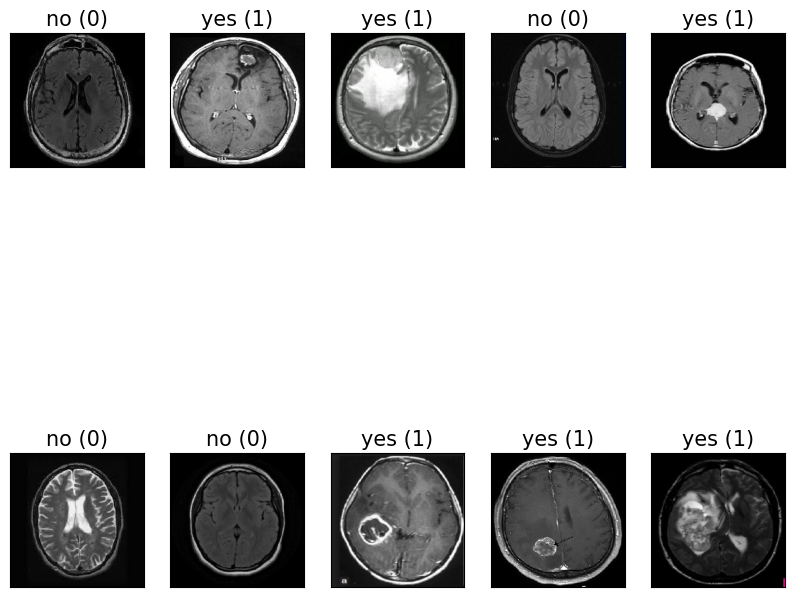

In [6]:
# Algunas imágenes y sus etiquetas
plt.figure(figsize=(10, 10))

for i in range(10):
    plt.subplot(2, 5,i + 1)
    index = np.random.randint(0, len(image_arrays))
    plt.imshow(image_arrays[index])
    plt.title(f'{labels[index]} ({encoded_labels[index]})', fontsize=15)
    plt.xticks([])
    plt.yticks([])
plt.show()

A continuación, separamos los datos en tres conjuntos: 
* `train` para entrenar el modelo,
* `val` para ajustar los hiperparámetros, y
* `test` para poner a prueba el modelo.

In [7]:
# Dividimos los datos en 80% para entrenamiento y 20% para validación y testeo
X_train, X_temp, y_train, y_temp = train_test_split(image_arrays, labels_array, test_size=0.2, random_state=23)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=23)

## **2. Clasificación con redes neuronales convolucionales (CNN)** <a class="anchor" id="cnn-classification"></a>

In [8]:
# Definimos el modelo de CNN
cnn_model = Sequential()

# Capa convolucional
cnn_model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(250, 250, 3)))
cnn_model.add(MaxPooling2D(2, 2)) # Reducir dimensionalidad (menor coste computacional)
cnn_model.add(Dropout(0.2)) # Prevenir sobreajuste

# Capa de aplanado para la transición de las capas convolucionales a las densas
cnn_model.add(Flatten())

# Capas densas
cnn_model.add(Dense(128, activation='relu'))
cnn_model.add(Dropout(0.5))
cnn_model.add(Dense(2, activation='sigmoid'))

# Compilamos el modelo
cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Entrenamiento del modelo
history = cnn_model.fit(X_train, y_train, epochs=10, validation_data=(X_val, y_val))

Epoch 1/10
7/7 [==============================] - 10s 1s/step - loss: 5.8415 - accuracy: 0.6040 - val_loss: 1.3978 - val_accuracy: 0.8800
Epoch 2/10
7/7 [==============================] - 9s 1s/step - loss: 2.4266 - accuracy: 0.7030 - val_loss: 0.3753 - val_accuracy: 0.8800
Epoch 3/10
7/7 [==============================] - 9s 1s/step - loss: 0.5681 - accuracy: 0.7822 - val_loss: 0.4247 - val_accuracy: 0.8400
Epoch 4/10
7/7 [==============================] - 9s 1s/step - loss: 0.3254 - accuracy: 0.8762 - val_loss: 0.4625 - val_accuracy: 0.8000
Epoch 5/10
7/7 [==============================] - 9s 1s/step - loss: 0.2611 - accuracy: 0.8960 - val_loss: 0.5207 - val_accuracy: 0.8400
Epoch 6/10
7/7 [==============================] - 9s 1s/step - loss: 0.1739 - accuracy: 0.9604 - val_loss: 0.6223 - val_accuracy: 0.8400
Epoch 7/10
7/7 [==============================] - 9s 1s/step - loss: 0.1167 - accuracy: 0.9752 - val_loss: 0.7170 - val_accuracy: 0.7600
Epoch 8/10
7/7 [========================

1/1 [==============================] - 0s 197ms/step
Test accuracy: 0.8846153616905212

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.86      0.75      0.80         8
           1       0.89      0.94      0.92        18

   micro avg       0.88      0.88      0.88        26
   macro avg       0.88      0.85      0.86        26
weighted avg       0.88      0.88      0.88        26
 samples avg       0.88      0.88      0.88        26


Matriz de confusión:


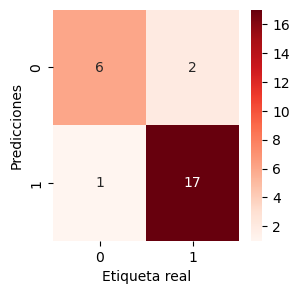

In [9]:
# Evaluación del modelo con el conjunto de testeo
test_loss, test_acc = cnn_model.evaluate(X_test, y_test)

# Predicciones en el conjunto de testeo
predictions = cnn_model.predict(X_test)
binary_predictions = (predictions >= 0.5).astype(int)

print(f'Test accuracy: {test_acc}')

# Informe de clasificación y matriz de confusión
print(f'\nInforme de clasificación:\n{classification_report(y_test, binary_predictions)}')

print('\nMatriz de confusión:')
plt.figure(figsize=(3, 3))
sns.heatmap(confusion_matrix(y_test.argmax(axis=1), binary_predictions.argmax(axis=1)), annot=True, cmap=plt.cm.Reds)
plt.xlabel("Etiqueta real")
plt.ylabel("Predicciones")
plt.show()

## **3. Clasificación con máquinas de soporte vectorial (SVM)** <a class="anchor" id="svm-classification"></a>

In [10]:
# Para entrenar el modelo es necesario "aplanar" los arrays de las imágenes
X_train_flatten = X_train.reshape(X_train.shape[0], -1)
X_val_flatten = X_val.reshape(X_val.shape[0], -1)
X_test_flatten = X_test.reshape(X_test.shape[0], -1)

# Definimos el modelo de SVM
svm_model = SVC(kernel='linear', random_state=23)

# Entrenamiento del modelo
svm_model.fit(X_train_flatten, y_train.argmax(axis=1))

SVC(kernel='linear', random_state=23)

Test accuracy: 0.8076923076923077

 Informe de clasificación:
              precision    recall  f1-score   support

           0       0.67      0.75      0.71         8
           1       0.88      0.83      0.86        18

    accuracy                           0.81        26
   macro avg       0.77      0.79      0.78        26
weighted avg       0.82      0.81      0.81        26


Matriz de confusión:


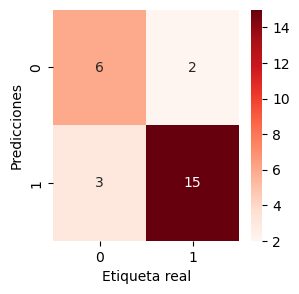

In [11]:
#Predicciones en el conjunto de testeo
svm_predictions = svm_model.predict(X_test_flatten)

print(f'Test accuracy: {accuracy_score(svm_predictions, y_test.argmax(axis=1))}')

# Informe de clasificación y matriz de confusión
print(f'\n Informe de clasificación:\n{classification_report(y_test.argmax(axis=1), svm_predictions)}')

print('\nMatriz de confusión:')
plt.figure(figsize=(3, 3))
sns.heatmap(confusion_matrix(y_test.argmax(axis=1), svm_predictions), annot=True, cmap=plt.cm.Reds)
plt.xlabel("Etiqueta real")
plt.ylabel("Predicciones")
plt.show()

## **4. Conclusión** <a class="anchor" id="conclusion"></a>

A primera vista se puede decir que los resultados son positivos, puesto que hemos obtenido una precisión de más del 80% en los dos modelos aplicados, aproximadamente un 88% para las redes convolucionales y un 80% para las máquinas de soporte vectorial. No obstante, es importante tener en cuenta las limitaciones del dataset escogido: tamaño reducido y una distribución desigual entre clases (61,3% son imágenes de tumores y 38,7% sin tumores). Todo esto a cambio de un tamaño de archivo más portable (\~8 MB).

El preprocesado también podría beneficiarse de mejoras adicionales. La variabilidad en los ratios de algunas imágenes hace que si aplicamos directamente el redimensionamiento puedan quedar deformadas y excluirlas reduciría un dataset ya de por sí limitado. Esto se podría salvar aplicando técnicas de _image augmentation_. Por otro lado, reducir el espacio _vacío_, recortando las imágenes a la región del cráneo, también podría favorecer los modelos.

La red convolucional se podría mejorar probando con distintas combinaciones de capas y parámetros, la combinación escogida da resultados positivos sin suponer un coste computacional demasiado elevado. En el caso del SVM, también se barajó la opción de combinar los conjuntos de validación y testeo (no se llega a utilizar el de validación), pero esta elección podría hacer que la comparación entre resultados no fuese del todo justa.

A pesar de la incertidumbre en torno a la validez de los resultados, el proyecto destaca el potencial de estas técnicas de aprendizaje automático en tareas de clasificación de imágenes.

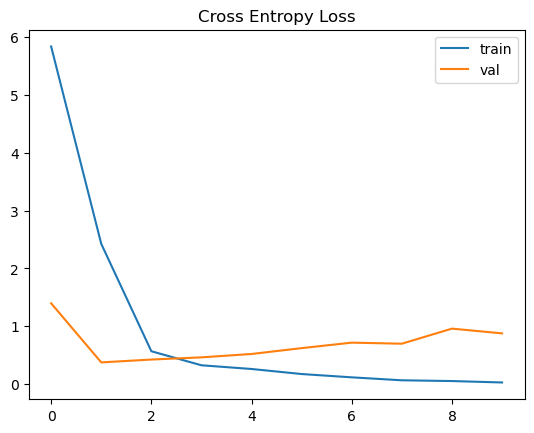

In [12]:
# Gráfica de la función Loss
plt.title('Cross Entropy Loss')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.show()